# 08 — Classical 4DVar vs 4DVarNet on Lorenz-63

This notebook compares:

1. **Classical 4DVar** — minimise the variational cost
   $U(x) = \alpha_{obs}\|m\odot(x-y)\|^2 + \alpha_{prior}\|x-\varphi(x)\|^2$
   with respect to $x$ using a gradient-descent optimisation loop in JAX.

2. **4DVarNet (learned)** — `FourDVarNet1D` trained end-to-end.

We compare reconstruction MSE and convergence behaviour.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import vardax
from vardax import (
    Batch1D,
    BilinAEPrior1D,
    FourDVarNet1D,
    variational_cost,
    variational_cost_grad,
    decomposed_loss,
)
from vardax._src.utils.dynamical_systems import simulate_lorenz63
from vardax._src.utils.patches import trajectory_to_xr_dataset, extract_patches
from vardax._src.utils.masks import regular_mask
from vardax._src.utils.noise import add_gaussian_noise
from vardax._src.utils.preprocessing import xr_to_batch1d
from vardax._src.utils.standardize import compute_scaler_params, apply_standardization

## 1. Prepare L63 data

In [2]:
key = jax.random.PRNGKey(0)
time_coords, states = simulate_lorenz63(
    key, sigma=10.0, rho=28.0, beta=8.0 / 3.0, dt=0.01, n_steps=5000, n_burn_in=1000
)
ds = trajectory_to_xr_dataset(states, time_coords, feature_names=["X", "Y", "Z"])
# Split the trajectory in time *before* cutting windows, so no window
# straddles the boundary: windows drawn at random from one trajectory and
# split afterwards would leak test timesteps into the training set.
n_time = ds.sizes["time"]
ds_train = extract_patches(ds.isel(time=slice(0, int(0.8 * n_time))), n_patches=160, n_timesteps=20, seed=42)
ds_test = extract_patches(ds.isel(time=slice(int(0.8 * n_time), None)), n_patches=40, n_timesteps=20, seed=43)
ds_train = regular_mask(ds_train, variable="state", obs_interval=2)
ds_test = regular_mask(ds_test, variable="state", obs_interval=2)
ds_train = add_gaussian_noise(ds_train, variable="state", sigma=0.5, seed=0, name="obs")
ds_test = add_gaussian_noise(ds_test, variable="state", sigma=0.5, seed=1, name="obs")
mean, std = compute_scaler_params(ds_train, variable="state", mask_variable="mask")
ds_train = apply_standardization(ds_train, variables=["state", "obs"], mean=mean, std=std)
ds_test = apply_standardization(ds_test, variables=["state", "obs"], mean=mean, std=std)

batch_train = xr_to_batch1d(ds_train, state_var="state", obs_var="obs", mask_var="mask")
batch_test = xr_to_batch1d(ds_test, state_var="state", obs_var="obs", mask_var="mask")
B, T, N = batch_test.input.shape
print(f"Test batch shape: {batch_test.input.shape}")

Test batch shape: (40, 20, 3)


## 2. Classical 4DVar — gradient descent on $x$

We use a fixed prior — a bilinear autoencoder pre-trained on clean training
windows, as in notebook [07](07_prior_pretraining_L63.ipynb) — and minimise
$U(x)$ with respect to $x$ directly, running a manual gradient-descent loop
so we can track the convergence trajectory.

In [3]:
import equinox as eqx
import optax

prior = BilinAEPrior1D(state_dim=N, latent_dim=8, n_time=T, key=jax.random.PRNGKey(5))
pre_opt = optax.adam(1e-2)
pre_state = pre_opt.init(eqx.filter(prior, eqx.is_array))


@eqx.filter_jit
def pretrain_step(prior, opt_state, x):
    loss, grads = eqx.filter_value_and_grad(lambda p: jnp.mean((x - p(x)) ** 2))(prior)
    updates, opt_state = pre_opt.update(grads, opt_state, prior)
    return eqx.apply_updates(prior, updates), opt_state, loss


for _ in range(300):
    prior, pre_state, pre_loss = pretrain_step(prior, pre_state, batch_train.target)
print(f"prior reconstruction MSE after pre-training: {float(pre_loss):.4f}")


# Initialise x from masked observations
x_classical = batch_test.input * batch_test.mask

classical_losses = []
# `variational_cost` is a *mean* over all B*T*N elements, so its gradient per
# element is tiny. Scaling the step by the element count gives a per-element
# step size `eta` (gradient descent on the equivalent sum cost), which lets
# the baseline actually converge within the step budget.
eta_classical = 0.2
n_classical_steps = 50
n_elem = x_classical.size

grad_fn = jax.jit(jax.value_and_grad(variational_cost))

for step in range(n_classical_steps):
    loss_val, grad = grad_fn(
        x_classical, batch_test, prior, alpha_obs=0.5, alpha_prior=0.5
    )
    x_classical = x_classical - eta_classical * n_elem * grad
    classical_losses.append(float(loss_val))

mse_classical = float(jnp.mean((x_classical - batch_test.target) ** 2))
print(f"Classical 4DVar MSE after {n_classical_steps} steps: {mse_classical:.4f}")

# Decomposed loss at convergence
dl = decomposed_loss(x_classical, batch_test, prior)
print(
    f"  obs={float(dl['obs']):.4f}, prior={float(dl['prior']):.4f}, total={float(dl['total']):.4f}"
)

prior reconstruction MSE after pre-training: 0.0058


Classical 4DVar MSE after 50 steps: 0.0068


  obs=0.0008, prior=0.0010, total=0.0017


## 3. 4DVarNet — trained end-to-end

In [4]:
model = FourDVarNet1D(
    state_dim=N, n_time=T, latent_dim=8, hidden_dim=16, n_solver_steps=10,
    key=jax.random.PRNGKey(1),
)

model, train_losses, _ = vardax.examples.fit_demo(
    model,
    [batch_train],
    n_epochs=10,
    lr=1e-3,
    verbose=False,
)
print(f"4DVarNet final train loss: {train_losses[-1]:.4f}")

out_4dvarnet = model(batch_test)
mse_4dvarnet = float(jnp.mean((out_4dvarnet - batch_test.target) ** 2))
print(f"4DVarNet test MSE: {mse_4dvarnet:.4f}")

4DVarNet final train loss: 0.3292


4DVarNet test MSE: 0.4065


## 4. Comparison: convergence and reconstruction quality

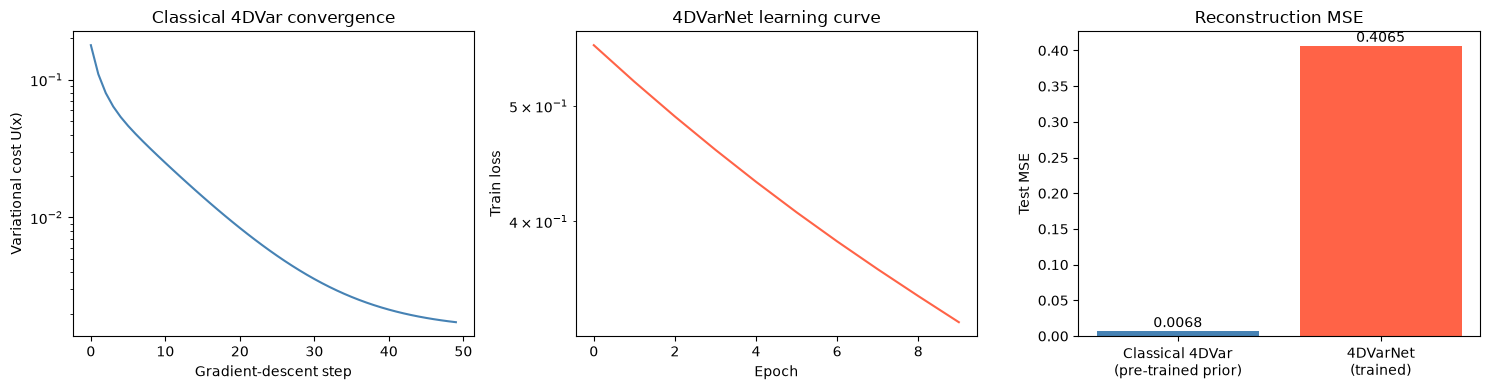

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Convergence of classical 4DVar
axes[0].semilogy(classical_losses, color="steelblue")
axes[0].set_xlabel("Gradient-descent step")
axes[0].set_ylabel("Variational cost U(x)")
axes[0].set_title("Classical 4DVar convergence")

# 4DVarNet learning curve
axes[1].semilogy(train_losses, color="tomato")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Train loss")
axes[1].set_title("4DVarNet learning curve")

# MSE bar chart
bars = axes[2].bar(
    ["Classical 4DVar\n(pre-trained prior)", "4DVarNet\n(trained)"],
    [mse_classical, mse_4dvarnet],
    color=["steelblue", "tomato"],
)
axes[2].set_ylabel("Test MSE")
axes[2].set_title("Reconstruction MSE")
for bar, val in zip(bars, [mse_classical, mse_4dvarnet]):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 0.001,
        f"{val:.4f}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

## 5. Visualise reconstructions side by side

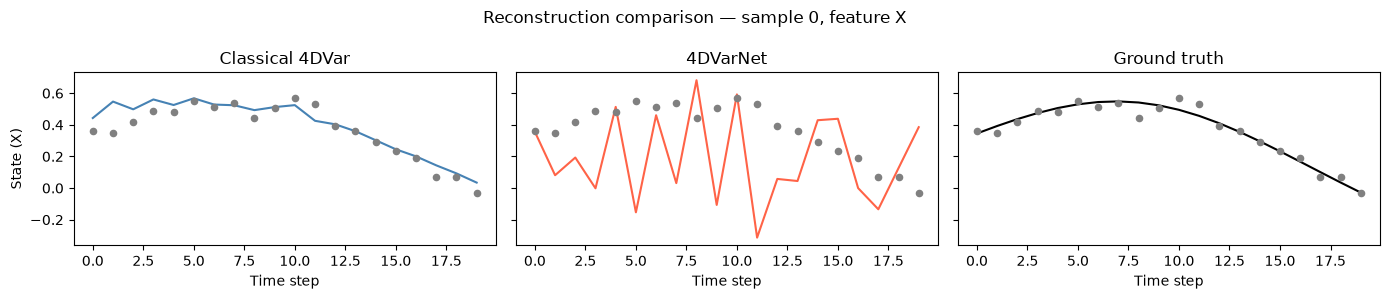

In [6]:
sample_idx = 0
feature_idx = 0

fig, axes = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
t_axis = range(T)

for ax, recon, label, color in zip(
    axes,
    [
        x_classical[sample_idx, :, feature_idx],
        out_4dvarnet[sample_idx, :, feature_idx],
        batch_test.target[sample_idx, :, feature_idx],
    ],
    ["Classical 4DVar", "4DVarNet", "Ground truth"],
    ["steelblue", "tomato", "black"],
):
    ax.plot(t_axis, recon, color=color, linewidth=1.5, label=label)
    ax.scatter(
        t_axis,
        batch_test.input[sample_idx, :, feature_idx],
        c="gray",
        s=20,
        zorder=5,
        label="Obs",
    )
    ax.set_title(label)
    ax.set_xlabel("Time step")

axes[0].set_ylabel("State (X)")
plt.suptitle(f"Reconstruction comparison — sample {sample_idx}, feature X")
plt.tight_layout()
plt.show()